# Model Selection for Buenos Aires Apartment Prices

## Objective and Dataset
Compare a training-mean baseline, multivariate OLS, Ridge, and Lasso on identical observations to identify the lowest observed test RMSE and examine prediction errors and coefficient sparsity. The five listing datasets describe apartments in Capital Federal.

Run this notebook with the repository root as the working directory. RMSE is reported in USD.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from category_encoders import OneHotEncoder
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from src.wrangle import clean_files

## Data Preparation and Train/Test Split
The shared cleaning function merges the files, retains Capital Federal apartments below USD 400,000, filters covered area between its 10th and 90th percentiles (nominally the middle 80%), extracts coordinates and neighborhood, and removes incomplete rows and unused columns. Price-derived predictors are excluded.

These area thresholds are learned before the split, a retained data-selection limitation. All models use the same four raw predictors and 80/20 split with `random_state=42`.

In [2]:
df = clean_files("data/buenos-aires-real-estate-*.csv")
target = "price_aprox_usd"
feature = [col for col in df.columns if col != target]
X, y = df[feature], df[target]
X_train_4, X_test_4, y_train_4, y_test_4 = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Cleaned dataset:", df.shape)
print("Predictors:", feature)
print("Training/test rows:", len(X_train_4), len(X_test_4))

Cleaned dataset: (6247, 5)
Predictors: ['surface_covered_in_m2', 'lat', 'lon', 'neighborhood']
Training/test rows: 4997 1250


## Evaluation Methodology
Every fitted pipeline one-hot encodes neighborhood and standardizes the encoded predictors. The Ridge and Lasso searches fit the entire pipeline inside each of five unshuffled folds, so validation rows do not determine encoding or scaling.

Ridge maximizes mean validation R² over 100 logarithmically spaced alphas from 0.01 to 10,000. Lasso minimizes mean validation MSE over 100 alphas from 0.0001 to 100. The selected pipelines are refitted on all training rows. Their different selection scores should be interpreted within each model family.

Training and test RMSE use the same function. The test-minus-training gap describes this split; its sign does not prove the presence or absence of overfitting.

In [3]:
def get_rmse_4(model, X, y_true):
    return root_mean_squared_error(y_true, model.predict(X))

## Mean Baseline and OLS
The baseline predicts the training-target mean for both splits. OLS uses all four raw predictors through the same encoding and scaling pipeline, without a coefficient penalty.

In [4]:
# Calculate mean
y_mean_4 = y_train_4.mean()
y_pred_baseline_train = [y_mean_4] * len(y_train_4)
y_pred_baseline_test = [y_mean_4] * len(y_test_4)
rmse_base_train = root_mean_squared_error(y_train_4, y_pred_baseline_train)
rmse_base_test = root_mean_squared_error(y_test_4, y_pred_baseline_test)

print(f"Baseline Train RMSE: ${rmse_base_train:,.2f}")
print(f"Baseline Test RMSE: ${rmse_base_test:,.2f}")

Baseline Train RMSE: $59,700.25
Baseline Test RMSE: $57,576.13


In [5]:
model_linear_4 = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    LinearRegression()
)

model_linear_4.fit(X_train_4, y_train_4)

rmse_linear_train = get_rmse_4(model_linear_4, X_train_4, y_train_4)
rmse_linear_test = get_rmse_4(model_linear_4, X_test_4, y_test_4)

print(f"Linear Regression Train RMSE: ${rmse_linear_train:,.2f}")
print(f"Linear Regression Test RMSE: ${rmse_linear_test:,.2f}")

Linear Regression Train RMSE: $34,200.43
Linear Regression Test RMSE: $33,088.37


## Ridge Cross-Validation
Ridge applies an L2 penalty. Alpha selection uses training-fold R²; the test set is evaluated after fitting.

In [6]:
from sklearn.model_selection import GridSearchCV, KFold

cv_folds_4 = KFold(n_splits=5, shuffle=False)
ridge_alphas_4 = np.logspace(-2, 4, 100)
ridge_search_4 = GridSearchCV(
    make_pipeline(OneHotEncoder(use_cat_names=True), StandardScaler(), Ridge()),
    param_grid={"ridge__alpha": ridge_alphas_4},
    scoring="r2", cv=cv_folds_4, refit=True
)
ridge_search_4.fit(X_train_4, y_train_4)
model_ridge_4 = ridge_search_4.best_estimator_
rmse_ridge_train = get_rmse_4(model_ridge_4, X_train_4, y_train_4)
rmse_ridge_test = get_rmse_4(model_ridge_4, X_test_4, y_test_4)
alpha_ridge_chosen = ridge_search_4.best_params_["ridge__alpha"]
print(f"Best Ridge alpha: {alpha_ridge_chosen:.6f}")
print(f"Ridge Train RMSE: ${rmse_ridge_train:,.2f}")
print(f"Ridge Test RMSE: ${rmse_ridge_test:,.2f}")


Best Ridge alpha: 49.770236
Ridge Train RMSE: $34,205.01
Ridge Test RMSE: $33,069.57


## Lasso Cross-Validation and Numerical Convergence
Lasso applies an L1 penalty with `max_iter=10000` and the default tolerance of `0.0001`. Convergence warnings are captured only around this search and counted; unrelated warnings remain visible. The original grid is retained.

A focused diagnostic of this same implementation established convergence in all five folds at the selected alpha (approximately 28.4803586844) and its immediate neighbors (approximately 24.7707635599 and 32.7454916288). The selected full-training refit also converged. Some much smaller candidates did not converge, leaving their validation scores uncertain: the optimum over the entire grid is not conclusively established, although the selected fitted candidate is numerically converged at the specified tolerance.

In [7]:
lasso_alphas_4 = np.logspace(-4, 2, 100)
lasso_search_4 = GridSearchCV(
    make_pipeline(OneHotEncoder(use_cat_names=True), StandardScaler(),
                  Lasso(max_iter=10000)),
    param_grid={"lasso__alpha": lasso_alphas_4},
    scoring="neg_mean_squared_error", cv=cv_folds_4, refit=True
)
with warnings.catch_warnings(record=True) as lasso_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    lasso_search_4.fit(X_train_4, y_train_4)
convergence_warning_count = sum(
    issubclass(item.category, ConvergenceWarning) for item in lasso_warnings
)
for item in lasso_warnings:
    if not issubclass(item.category, ConvergenceWarning):
        warnings.warn_explicit(item.message, item.category, item.filename, item.lineno)
print("Lasso grid convergence warnings:", convergence_warning_count)
print("Some candidate scores are numerically uncertain; full-grid optimality is unconfirmed.")
model_lasso_4 = lasso_search_4.best_estimator_
rmse_lasso_train = get_rmse_4(model_lasso_4, X_train_4, y_train_4)
rmse_lasso_test = get_rmse_4(model_lasso_4, X_test_4, y_test_4)
alpha_lasso_chosen = lasso_search_4.best_params_["lasso__alpha"]
print(f"Best Lasso alpha: {alpha_lasso_chosen:.6f}")
print(f"Lasso Train RMSE: ${rmse_lasso_train:,.2f}")
print(f"Lasso Test RMSE: ${rmse_lasso_test:,.2f}")


Lasso grid convergence warnings: 293
Some candidate scores are numerically uncertain; full-grid optimality is unconfirmed.
Best Lasso alpha: 28.480359
Lasso Train RMSE: $34,202.52
Lasso Test RMSE: $33,071.30


In [8]:
selected_lasso = model_lasso_4.named_steps["lasso"]
centered_y = y_train_4.to_numpy() - y_train_4.mean()
refit_gap_threshold = selected_lasso.tol * np.dot(centered_y, centered_y) / len(centered_y)
print("Selected refit iterations:", selected_lasso.n_iter_)
print("Iteration limit reached:", selected_lasso.n_iter_ >= selected_lasso.max_iter)
print("Refit duality gap / stopping threshold:", selected_lasso.dual_gap_, refit_gap_threshold)

Selected refit iterations: 165
Iteration limit reached: False
Refit duality gap / stopping threshold: 342723.0531003172 356411.9671978928


## Model Performance Comparison
All candidates are evaluated on the same holdout. Choosing a model from these test results reuses that holdout for selection, reducing its independence as a final benchmark.

In [9]:
# Build Results Table
data_4 = {
    "Model": ["Baseline", "Linear Regression", "Ridge (CV-tuned)", "Lasso (CV-tuned)"],
    "Train_RMSE": [
        rmse_base_train,
        rmse_linear_train,
        rmse_ridge_train,
        rmse_lasso_train
    ],
    "Test_RMSE": [
        rmse_base_test,
        rmse_linear_test,
        rmse_ridge_test,
        rmse_lasso_test
    ]
}

df_results_4 = pd.DataFrame(data_4)
df_results_4["Gap"] = df_results_4["Test_RMSE"] - df_results_4["Train_RMSE"]
df_results_4 = df_results_4.set_index("Model")

print("\n" + "="*60)
print("MODEL COMPARISON TABLE")
print("="*60)
print(df_results_4.round(2))
print("="*60)


MODEL COMPARISON TABLE
                   Train_RMSE  Test_RMSE      Gap
Model                                            
Baseline             59700.25   57576.13 -2124.12
Linear Regression    34200.43   33088.37 -1112.06
Ridge (CV-tuned)     34205.01   33069.57 -1135.43
Lasso (CV-tuned)     34202.52   33071.30 -1131.22


In [10]:
best_model = df_results_4["Test_RMSE"].idxmin()
print("Lowest observed test RMSE:", best_model)
print("Lasso minus Ridge test RMSE (USD):", rmse_lasso_test - rmse_ridge_test)

Lowest observed test RMSE: Ridge (CV-tuned)
Lasso minus Ridge test RMSE (USD): 1.7296650489151943


## Prediction and Residual Diagnostics
The selected Lasso predictions are reused for both plots. Departures from the diagonal expose prediction errors; residuals (actual minus predicted) reveal patterns and changes in spread. These plots do not establish that every systematic relationship has been captured or provide prediction intervals.

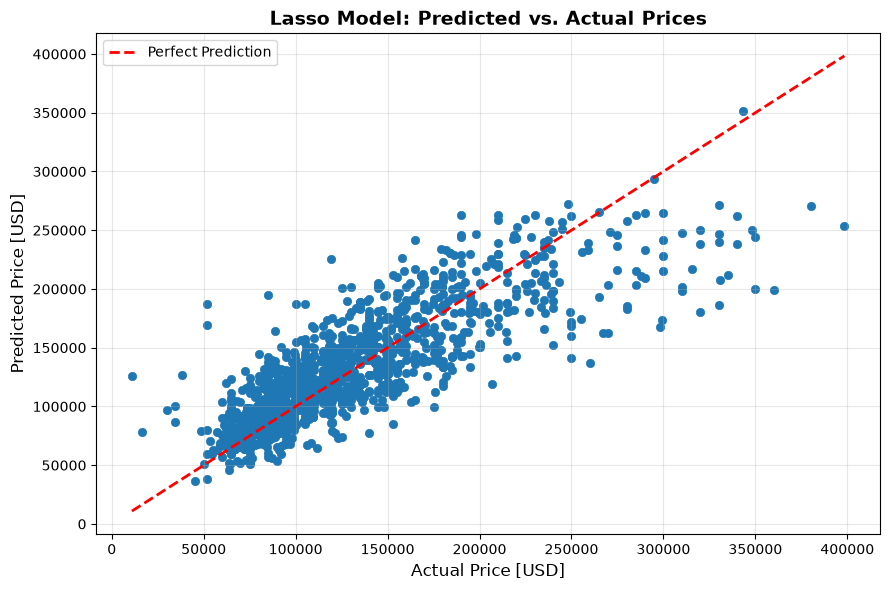

In [11]:
y_pred_lasso_4 = model_lasso_4.predict(X_test_4)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(y_test_4, y_pred_lasso_4, linewidth=0.5)

ideal_line = np.linspace(y_test_4.min(), y_test_4.max(), 100)
ax.plot(ideal_line, ideal_line, color="red", linestyle="--", linewidth=2, label="Perfect Prediction")

ax.set_xlabel("Actual Price [USD]", fontsize=12)
ax.set_ylabel("Predicted Price [USD]", fontsize=12)
ax.set_title("Lasso Model: Predicted vs. Actual Prices", fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

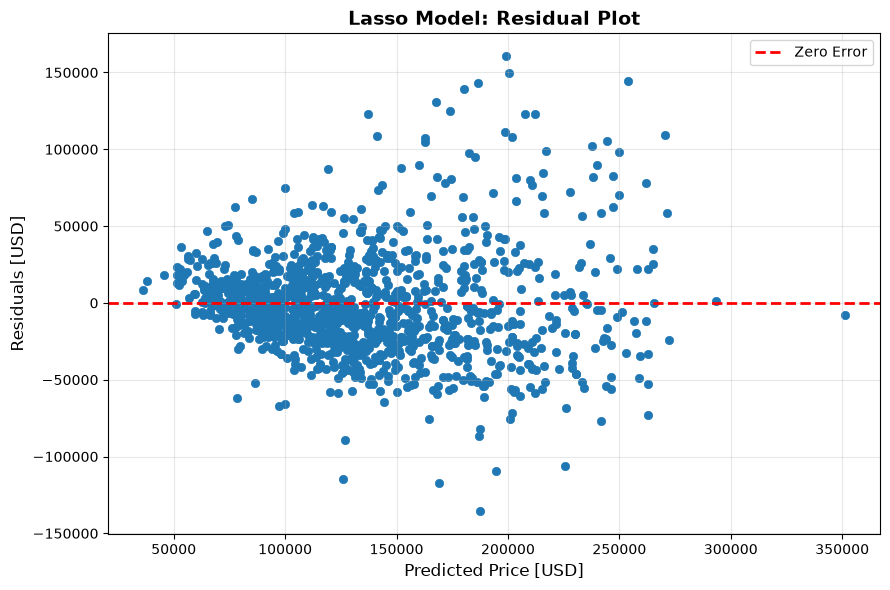

In [12]:
residuals_4 = y_test_4 - y_pred_lasso_4

fig_res, ax_res = plt.subplots(figsize=(9, 6))
ax_res.scatter(y_pred_lasso_4, residuals_4, linewidth=0.5)
ax_res.axhline(y=0, color='r', linestyle='--', linewidth=2, label='Zero Error')
ax_res.set_xlabel("Predicted Price [USD]", fontsize=12)
ax_res.set_ylabel("Residuals [USD]", fontsize=12)
ax_res.set_title("Lasso Model: Residual Plot", fontsize=14, fontweight='bold')
ax_res.legend(fontsize=10)
ax_res.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Coefficient Importance and Sparsity
Coefficients describe USD changes per one training standard deviation of an encoded predictor, conditional on the others. All neighborhood indicators are retained without an explicitly omitted reference category. Their magnitudes depend on scaling, prevalence, correlated inputs, and regularization; they are fitted associations rather than causal importance or direct neighborhood premiums.

Exact zeros describe exclusion at this fitted penalty, not proof that a predictor contains no useful information.

In [13]:
# Extract from pipeline
coefs_4 = model_lasso_4.named_steps["lasso"].coef_
feature_names_4 = model_lasso_4.named_steps["onehotencoder"].get_feature_names_out()

feat_imp_4 = pd.Series(coefs_4, index=feature_names_4)

print(f"Total features: {len(feat_imp_4)}")
print(f"Non-zero features: {(feat_imp_4 != 0).sum()}")
print("\nTop 5 positive coefficients:")
print(feat_imp_4.nlargest(5))
print("\nTop 5 negative coefficients:")
print(feat_imp_4.nsmallest(5))

Total features: 59
Non-zero features: 58

Top 5 positive coefficients:
surface_covered_in_m2         40349.832111
neighborhood_Puerto Madero     9784.686505
neighborhood_Palermo           9719.674428
lat                            8768.871943
neighborhood_Belgrano          7341.989624
dtype: float64

Top 5 negative coefficients:
neighborhood_Balvanera      -5432.128705
neighborhood_Boca           -4763.630095
neighborhood_Once           -4534.763568
neighborhood_Congreso       -3366.093485
neighborhood_Constitución   -2751.090114
dtype: float64


In [14]:
zero_features_4 = (feat_imp_4 == 0).sum()
total_features_4 = len(feat_imp_4)
percent_eliminated_4 = (zero_features_4 / total_features_4) * 100

print(f"Lasso eliminated {zero_features_4} out of {total_features_4} features.")
print(f"Percentage eliminated: {percent_eliminated_4:.1f}%")

Lasso eliminated 1 out of 59 features.
Percentage eliminated: 1.7%


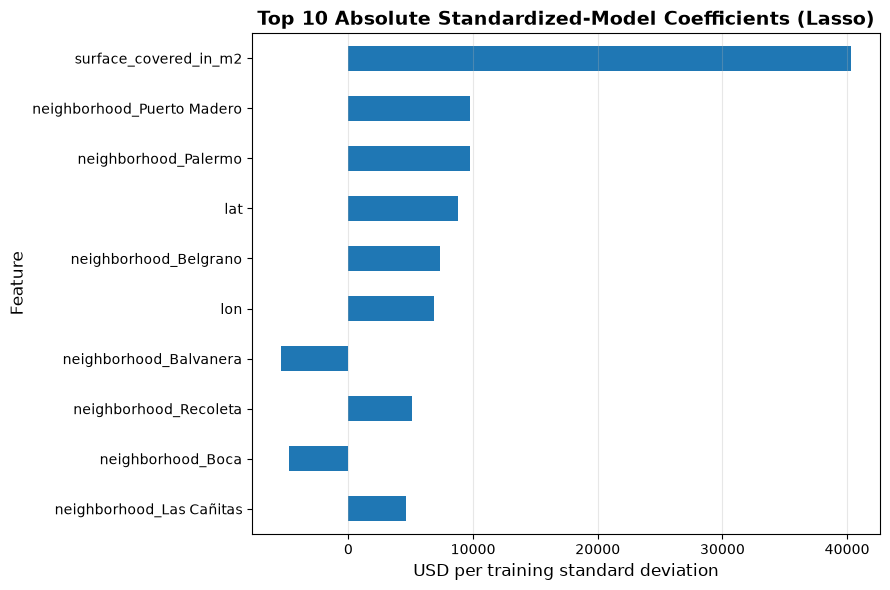

In [15]:
fig_feat, ax_feat = plt.subplots(figsize=(9, 6))
feat_imp_4.sort_values(key=abs).tail(10).plot(kind="barh", ax=ax_feat)
ax_feat.set_title("Top 10 Absolute Standardized-Model Coefficients (Lasso)", fontsize=14, fontweight='bold')
ax_feat.set_xlabel("USD per training standard deviation", fontsize=12)
ax_feat.set_ylabel("Feature", fontsize=12)
ax_feat.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
top_feature_4 = feat_imp_4.abs().idxmax()
top_coefficient_4 = feat_imp_4.loc[top_feature_4]

print(f"The feature with the largest absolute coefficient is: {top_feature_4}")
print(f"Its coefficient is: ${top_coefficient_4:,.2f}")

The feature with the largest absolute coefficient is: surface_covered_in_m2
Its coefficient is: $40,349.83


## Findings
Ridge has the lowest observed test RMSE in the recomputed comparison, but its advantage over Lasso is extremely small. Neither reliable superiority nor statistical equivalence has been established. All three fitted linear models improve substantially on the mean baseline on this split.

The selected Lasso is numerically converged, but its full-grid selection remains provisional because some low-alpha candidates did not converge. Its measured zero-coefficient count indicates modest sparsity, rather than dramatic feature compression. The largest absolute standardized coefficient describes this particular fitted model, not the strongest independent price signal.

## Limitations
- The test set has been inspected across modeling stages and used to choose the leading candidate; it is not an independent final evaluation.
- Unconverged low-alpha Lasso candidates prevent conclusive identification of the full-grid optimum.
- Covered-area percentiles are learned across the filtered dataset before splitting; fold-safe model preprocessing does not remove that upstream selection limitation.
- One train/test split cannot establish stability of the small performance differences.
- Price caps, area filtering, and complete-case selection restrict applicability to the retained apartment listings.
- Residual patterns suggest limits of linear predictions and potentially unequal error variance. No coefficient confidence intervals or prediction intervals are estimated.
- Standardized coefficients are conditional associations, and sparsity does not establish causal relevance or deployment readiness.